# Task 7: Walmart Sales Forecasting

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("Walmart_Store_sales.csv")
df.tail()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667
6434,45,26-10-2012,760281.43,0,58.85,3.882,192.308899,8.667


In [3]:
df.columns = df.columns.str.strip()
df.shape

(6435, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


## Data cleaning and Exploring historical sales

In [5]:
required = ["Date", "Weekly_Sales"]
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Weekly_Sales"] = pd.to_numeric(df["Weekly_Sales"], errors="coerce")
df = df.dropna(subset=required).copy()
df["Date"]

0      2010-05-02
1      2010-12-02
4      2010-05-03
5      2010-12-03
8      2010-02-04
          ...    
6422   2012-03-08
6423   2012-10-08
6427   2012-07-09
6431   2012-05-10
6432   2012-12-10
Name: Date, Length: 2565, dtype: datetime64[ns]

In [6]:
print("Cleaned rows:", len(df))
print("Date range:", df.Date.min(), "to", df.Date.max())

Cleaned rows: 2565
Date range: 2010-01-10 00:00:00 to 2012-12-10 00:00:00


In [7]:
daily = df.groupby("Date", as_index=False)["Weekly_Sales"].sum().sort_values("Date")
daily.head()

,Date,Weekly_Sales
0,2010-01-10,42239875.87
1,2010-02-04,50423831.26
2,2010-02-07,48917484.50
3,2010-03-09,47194257.61
4,2010-03-12,49909027.88


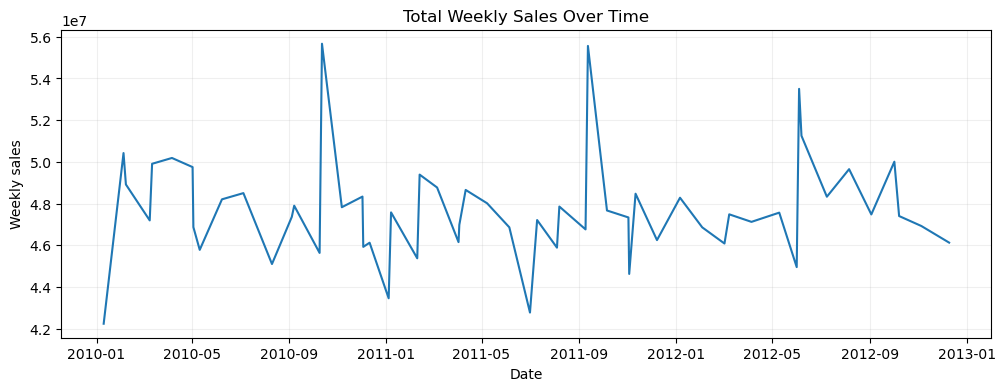

In [8]:
plt.figure(figsize=(12,4))
plt.plot(daily.Date, daily.Weekly_Sales)
plt.title("Total Weekly Sales Over Time"); plt.xlabel("Date"); plt.ylabel("Weekly sales")
plt.grid(alpha=.2); plt.show()

## Create time-based and lag features

In [9]:
df = df.sort_values(["Store"] + ["Date"]).copy()

df["Store"] = pd.to_numeric(df["Store"], errors="coerce")

In [10]:
df["year"] = df.Date.dt.year
df["month"] = df.Date.dt.month
df["week"] = df.Date.dt.isocalendar().week
df["day_of_year"] = df.Date.dt.dayofyear
df["quarter"] = df.Date.dt.quarter
df["time_index"] = (df.Date - df.Date.min()).dt.days

In [11]:
s = df["Weekly_Sales"]
df["lag_1"] = s.shift(1); 
df["lag_2"] = s.shift(2);
df["lag_4"] = s.shift(4)
df["rolling_mean_4"] = s.shift(1).rolling(4).mean()

In [12]:
df = df.dropna(subset=["lag_1", "lag_2", "lag_4", "rolling_mean_4"]).copy()
print("Rows after lag creation:", len(df))
display(df.head())

Rows after lag creation: 2561


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,year,month,week,day_of_year,quarter,time_index,lag_1,lag_2,lag_4,rolling_mean_4
43,1,2010-03-12,1548033.78,0,49.27,2.708,211.607193,7.838,2010,3,10,71,1,61,1540163.53,1492418.14,1453329.50,1.520220e+06
17,1,2010-04-06,1615524.71,0,80.69,2.705,211.176428,7.808,2010,4,14,96,2,86,1548033.78,1540163.53,1594968.28,1.543896e+06
0,1,2010-05-02,1643690.90,0,42.31,2.572,211.096358,8.106,2010,5,17,122,2,112,1615524.71,1548033.78,1492418.14,1.549035e+06
4,1,2010-05-03,1554806.68,0,46.50,2.625,211.350143,8.106,2010,5,18,123,2,113,1643690.90,1615524.71,1540163.53,1.586853e+06
39,1,2010-05-11,1551659.28,0,58.74,2.689,211.956394,7.838,2010,5,19,131,2,121,1554806.68,1643690.90,1548033.78,1.590514e+06


## Preparing features and train/test split

In [13]:
feature_cols = ["Store","year","month","week","day_of_year","quarter","time_index","lag_1","lag_2","lag_4","rolling_mean_4"]
df = df.sort_values("Date").copy()
split = int(len(df) * 0.8)

In [14]:
train = df.iloc[:split]
test = df.iloc[split:]
train

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,year,month,week,day_of_year,quarter,time_index,lag_1,lag_2,lag_4,rolling_mean_4
1607,12,2010-01-10,850936.26,0,85.20,3.001,126.234600,14.313,2010,1,1,10,1,0,1311965.09,1300147.07,1574287.76,1.393843e+06
4038,29,2010-01-10,474698.01,0,69.31,2.717,132.756800,10.524,2010,1,1,10,1,0,1205536.71,1264575.18,1572966.15,1.328048e+06
1464,11,2010-01-10,1182490.46,0,75.11,2.603,214.984655,7.564,2010,1,1,10,1,0,1713889.11,1792345.30,2218595.80,1.901317e+06
6183,44,2010-01-10,300152.45,0,68.74,2.853,126.234600,7.610,2010,1,1,10,1,0,619369.72,640159.04,662198.65,6.413215e+05
5325,38,2010-01-10,360256.58,0,85.20,3.001,126.234600,14.313,2010,1,1,10,1,0,521810.75,527983.04,527041.46,5.194500e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5408,38,2012-04-05,491755.69,0,76.03,4.171,131.136000,11.627,2012,4,14,96,2,816,469311.17,457711.68,435579.70,4.584295e+05
3835,27,2012-04-05,1669388.45,0,53.68,4.124,142.017793,8.253,2012,4,14,96,2,816,1705810.84,1564246.02,1900638.60,1.670005e+06
689,5,2012-04-05,360932.69,0,77.10,3.749,222.259472,5.801,2012,4,14,96,2,816,324195.17,333948.00,359867.80,3.443043e+05
5694,40,2012-04-05,993311.59,0,44.47,3.991,138.033200,4.125,2012,4,14,96,2,816,1068346.76,979552.34,1037464.27,1.003274e+06


In [15]:
X_train = train[feature_cols]
y_train = train["Weekly_Sales"]
print("Train period:", train.Date.min(), "to", train.Date.max())

Train period: 2010-01-10 00:00:00 to 2012-04-05 00:00:00


In [16]:
X_test = test[feature_cols]
y_test = test["Weekly_Sales"]
print("Test period:", test.Date.min(), "to", test.Date.max())

Test period: 2012-04-05 00:00:00 to 2012-12-10 00:00:00


## Training regression models and evaluation

In [17]:
models = {
    "Random Forest": RandomForestRegressor(n_estimators=250, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42)
}

In [18]:
records, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted[name] = model
    records.append({"Model":name, "MAE":mean_absolute_error(y_test,pred), "RMSE":np.sqrt(mean_squared_error(y_test,pred))})

In [19]:
comparison = pd.DataFrame(records).sort_values("RMSE")
display(comparison)

,Model,MAE,RMSE
0,Random Forest,70400.072414,105366.005438
1,HistGradientBoosting,78614.070339,116317.710360


In [20]:
best_name = comparison.iloc[0]["Model"]
best_model = fitted[best_name]

In [21]:
predictions = best_model.predict(X_test)

## Plot of Actual sales versus Predicted sales

In [22]:
plot_df = test[["Date"]].copy()
plot_df["Actual_Sales"] = y_test.values
plot_df["Predicted_Sales"] = predictions
plot_df = plot_df.sort_values("Date")

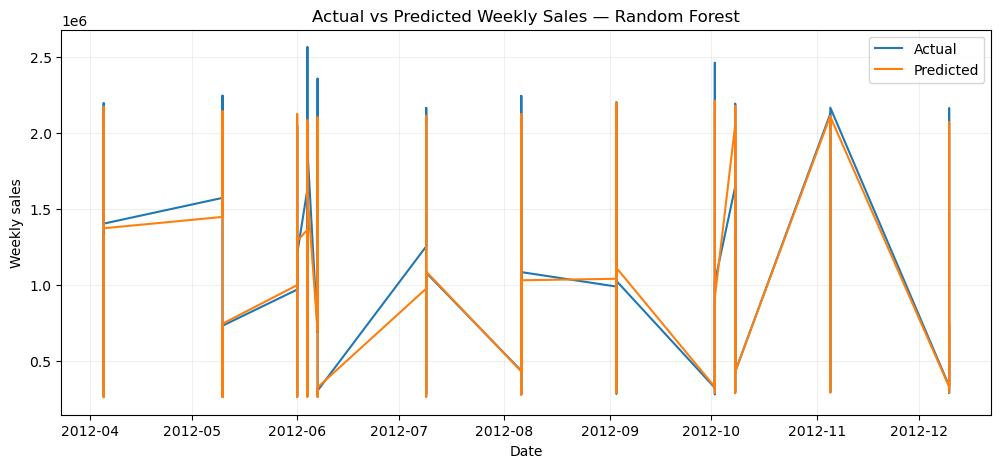

In [23]:
plt.figure(figsize=(12,5))
plt.plot(plot_df.Date, plot_df.Actual_Sales, label="Actual")
plt.plot(plot_df.Date, plot_df.Predicted_Sales, label="Predicted")
plt.title(f"Actual vs Predicted Weekly Sales — {best_name}")
plt.xlabel("Date"); plt.ylabel("Weekly sales"); plt.legend(); plt.grid(alpha=.2); plt.show()

In [24]:
joblib.dump(best_model, "best_sales_forecasting_model.joblib")

['best_sales_forecasting_model.joblib']

In [25]:
comparison.to_csv("sales_model_comparison.csv", index=False)
plot_df.to_csv("sales_test_predictions.csv", index=False)
print("Best model by RMSE:", best_name)
print("Saved model, comparison metrics, and test predictions.")

Best model by RMSE: Random Forest
Saved model, comparison metrics, and test predictions.


## Conclusion 
Random Forest outperformed HistgradientBoosting with a lower MAE and RMSE

Sales show high volatility with recurring seasonal spikes and sharp drops with no long term trend. 